# Multimodal Music Analysis

The target of this project is the implementation of a complete pipeline for extracting knowledge from music data by combining two different modalities: **Audio** and **Text**. The project is split into two parts:  
1. Preprocessing of the data, generation of embeddings and researching analysis.
2. Classification, Fusion and Evaluation.  
  
This notebook contains the implementation of part 1.


**Contributors**

|         Name         |          AM          |
| -------------------- | -------------------- |
| Διονύσιος Κοτσίρης   |   1115201900089      |
| Ιωάννης Οικονομίδης  |   1115201600120      |

Requirements:

In [ ]:
%pip install seaborn
%pip install datasets
%pip install matplotlib
%pip install vaderSentiment
%pip install kneed
%pip install contractions
%pip install pyspellchecker
%pip install scikit-learn
%pip install pandas
%pip install wordcloud
%pip install tensorflow
%pip install gensim
%pip install nltk

## **Introduction**  

Firstly, we focus on preprocessing our data and create one final dataframe to work on. We keep a subset of the total songs with the necessary columns to complete our research.  
- We keep songs that belong to the following genres:  
`"latin", "classical", "metal", "jazz", "rap"`  
having in mind the difference and the fame of these genres.  

- We keep all the songs that belong to multiple genres, so we introduce a new column in our dataframe `main_genre` to express the main genre of each song

- We extract the lyrics of each song after parsing the text files (form of the files: `{song_id}.txt`)

- We collect the MFCC stats for each song and we store them as vectors (1x104) for each song in our dataframe.

After, we extract audio and text embeddings from our MFCC stats in order to reduce the dimensionality of the vectors we will work on later. We follow this steps:  

- Extracting audio embeddings from the MFCC stats using Autoencoder and PCA.

- Extraction text embeddings from the lyrics of the song using the `Word2Vec` model from gensim.

In the last part, we visualise and analyse our researching results.

## 1. Data Collection


In [1]:
import pandas as pd
import os
import re

import numpy as np
import tensorflow as tf
import sklearn

import matplotlib.pyplot as plt

- Run the code in the next sections for pre-processing the data 
- In case the file already exists, the next sections are skipped automatically

In [2]:
def normalize_genre(genre, genres_list):
    if genre is None:
        return None
    
    # lowercase
    genre = genre.lower()

    # remove spaces and hyphens
    genre = re.sub(r"[\\-]+", "", genre)
    
    for g in genres_list:
        if g in genre:
            return g

    return genre

def filter_by_genres(df, genres_list):

    df["genres"] = df['genres'].apply(
            lambda x: list(set(str(x).split(",")))
        )
    df["main_genre"] = df['genres'].apply(
            lambda x: normalize_genre(x[0].strip(), genres_list)
        )

    return df[df["main_genre"].isin(genres_list)]

In [3]:
def create_lyrics_df(target_ids, path='data/processed_lyrics'):
    # --- Filtering the lyrics of the songs ---
    lyrics_folder = path

    lyrics_data = []

    for filename in os.listdir(lyrics_folder):
        if filename.endswith('.txt'):
            song_id = filename.replace('.txt', '')
            
            if song_id in target_ids:
                file_path = os.path.join(lyrics_folder, filename)
                
                with open(file_path, 'r', encoding='utf-8') as f:
                    lyrics_text = f.read()
                
                lyrics_data.append({
                    'id': song_id,
                    'lyrics': lyrics_text
                })

    lyrics_df = pd.DataFrame(lyrics_data)
    return lyrics_df

In [4]:
def merge_dataframes(dfs, merge_on):
    merged_df = dfs[0]

    for df in dfs[1:]:
        merged_df = pd.merge(merged_df, df, on=merge_on)

    return merged_df


In [5]:

def collect_data():
    # --- Importing the datasets ---
    genres_df = pd.read_csv('data/id_genres.csv', sep='\t') 
    information_df = pd.read_csv('data/id_information.csv', sep='\t')
    tags_df = pd.read_csv('data/id_tags.csv', sep='\t')
    mfcc_stats_df = pd.read_csv('data/id_mfcc_stats.tsv', sep='\t').dropna()

    # ---- Group mfcc stats in one column for better data ----
    mfcc_stats_df = mfcc_stats_df.copy()

    mfcc_columns = [col for col in mfcc_stats_df.columns if 'mfcc' in col.lower() or 'cov' in col.lower()]

    mfcc_stats_df['audio_stats'] = mfcc_stats_df[mfcc_columns].values.tolist()

    audio_stats_df = mfcc_stats_df.drop(columns=mfcc_columns)

    # --- Filtering the genres dataset to only include the top n most common genres ---
    genres_list = ["latin", "classical", "metal", "jazz", "rap"]
    filtered_genres_df = filter_by_genres(genres_df, genres_list)

    # --- Create dataframe with the lyrics of the songs ---
    lyrics_df = create_lyrics_df(target_ids=set(filtered_genres_df['id'].astype(str)))

    # --- Merging dataframes ---
    dataframes = [filtered_genres_df, information_df, tags_df, audio_stats_df, lyrics_df]
    df = merge_dataframes(dataframes, "id")

    # --- Handling missing and duplicate values ---
    df = df[df['lyrics'].notna()]
    df = df[df['genres'].notna()]
    df = df[df['genres'].str.strip() != '']
    df = df.drop_duplicates(subset='id', keep='first')

    return df
    

In [6]:
final_df_path = "data/final_data.pkl"
if (os.path.isfile(path=final_df_path)):
    data = pd.read_pickle(final_df_path,)
else:
    data = collect_data()
    data = data.drop(columns=["artist", "album_name"])
    data.to_pickle(final_df_path)
    

data.head()

,id,genres,main_genre,song,tags,audio_stats,lyrics
0,006TYKNjNxWjfKjy,"[symphonic metal, symphonic power metal, power...",metal,Flames of Revenge,"symphonic metal,power metal,symphonic power metal","[23.30799674987793, -8.152815818786621, -17.38...",princess must assist death endur tragic pain c...
1,00i0OB17z3m3yamO,"[alternative metal, alternative rock, rock]",metal,Sign of the Times,"alternative rock,rock,alternative metal,altern...","[24.25779724121093, -10.212427139282228, -4.85...",sign time anoth mountain climb sun burn hot fl...
2,00mLjKFmaTv9MdaB,"[rap, hip hop, pop]",rap,Boom Boom Pow,"dance,hip hop,pop,hip-hop,rap","[20.77475357055664, -6.112589359283447, -10.24...",get get get get get get get get boom boom boom...
3,01ScM29f0wF2Mnkq,"[rap, indie pop, electronic]",rap,Implicit Demand for Proof,"electronic,alternative,rap,indie,indie pop","[21.80247497558593, 2.8943941593170166, -16.29...",know liar know could set fire day go ahead mak...
4,01gyRHLquwXDlhkO,[rap],rap,Somebody's Gotta Die,"rap,hip-hop,gangsta rap,east coast rap","[22.731481552124023, -12.233457565307615, 2.38...",sittin crib dreamin leer jet coup way salt sho...


## 2. Feature Extraction

### **Audio Embeddings**

### Autoencoder
Creating and training a simple Autoencoder to compress the vector of the audio embedding to a vector with fewer dimensions.

In [7]:
class Autoencoder(tf.keras.Model):
    def __init__(self, input_dim, encoding_dim=32):
        super(Autoencoder, self).__init__()

        layers = tf.keras.layers

        self.encoder = tf.keras.Sequential([
            layers.Input(shape=(input_dim,)),
            layers.Dense(64, activation='relu'),
            layers.BatchNormalization(),
            layers.Dropout(0.2),
            layers.Dense(encoding_dim, activation='relu')
        ])

        self.decoder = tf.keras.Sequential([
            layers.Input(shape=(encoding_dim,)),
            layers.Dense(64, activation='relu'),
            layers.BatchNormalization(),
            layers.Dropout(0.2),
            layers.Dense(input_dim, activation='linear')
        ])

    def call(self, x):
        encoded = self.encoder(x)
        decoded = self.decoder(encoded)
        return decoded

In [8]:
from sklearn.preprocessing import StandardScaler
from keras.callbacks import EarlyStopping, TensorBoard
from sklearn.model_selection import train_test_split


'''
Function to train the autoencoder.
Arguments:  - scaled audio_stats from the dataframe ready for training
            - optional: hyperparameters for the training
Returns:    - training history for visualization
            - the trained autoencoder
'''
def autoencoder_training(audio_stats, encoding_dim=32, optimizer="adam", loss="mse",
                         epochs=100, batch_size=32, early_stopping_epoch=20):

    input_dim = audio_stats.shape[1]

    # --- autoencoder ---
    autoencoder = Autoencoder(input_dim, encoding_dim)

    autoencoder.compile(optimizer=optimizer, loss=loss)

    # --- autoencoder training ---
    early_stopping = EarlyStopping(
        monitor='val_loss',
        patience=early_stopping_epoch,
        restore_best_weights=True
    )
    X_train, X_val = train_test_split(audio_stats, test_size=0.2, random_state=42)

    training = autoencoder.fit(
                        X_train, X_train,
                        validation_data=(X_val, X_val),
                        epochs=epochs,
                        batch_size=batch_size,
                        shuffle=True,
                        callbacks=[early_stopping]
                    )

 
    return training, autoencoder    


In [9]:
# --- Extraction the audio embeddings from the audio stats column ---
audio_embeddings = np.array(data["audio_stats"].to_list(), dtype=float)
scaler = StandardScaler()
audio_embed_train = scaler.fit_transform(audio_embeddings)

training, autoencoder = autoencoder_training(audio_stats=audio_embed_train, epochs=200, optimizer="adam", early_stopping_epoch=5)



Epoch 1/200
433/433 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - loss: 0.6761 - val_loss: 0.5820
Epoch 2/200
433/433 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - loss: 0.4684 - val_loss: 0.4730
Epoch 3/200
433/433 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - loss: 0.3998 - val_loss: 0.4299
Epoch 4/200
433/433 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - loss: 0.3659 - val_loss: 0.3953
Epoch 5/200
433/433 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - loss: 0.3399 - val_loss: 0.3750
Epoch 6/200
433/433 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.3191 - val_loss: 0.3543
Epoch 7/200
433/433 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - loss: 0.3034 - val_loss: 0.3401
Epoch 8/200
433/433 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - loss: 0.2939 - val_loss: 0.3335
Epoch 9/200
433/433 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.2876 - val_loss: 0.3254
Epoch 10/200
433/433 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - loss: 0.2839 - val_loss: 0.3211
Epoch 11/200
433/433 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.2812 - val_loss: 0.3212
Epoch 12/200
433/433 ━━━━━━━━━━━━━━━━━━━━

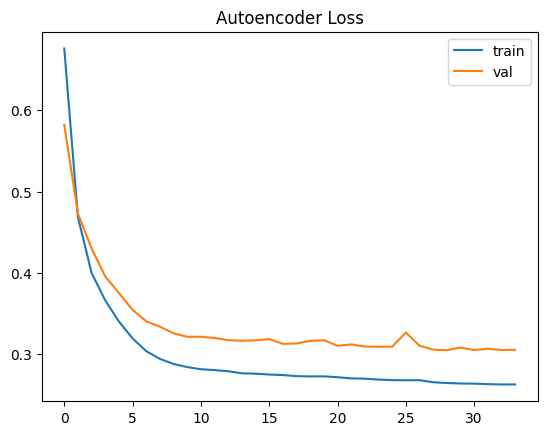

In [10]:
plt.plot(training.history['loss'], label='train')
plt.plot(training.history['val_loss'], label='val')
# plt.ylim(0, 1.0)
plt.legend()
plt.title("Autoencoder Loss")
plt.show()

In [15]:
# --- final compresses audio embeddings with 32 dim ---

autoenc_audio_embeddings = autoencoder.encoder.predict(audio_embed_train)
print(autoenc_audio_embeddings.shape)
np.save("data/audio_embeddings.npy", autoenc_audio_embeddings)

541/541 ━━━━━━━━━━━━━━━━━━━━ 0s 470us/step
(17299, 32)


### Principal Component Analysis (PCA)

In [12]:
from sklearn.decomposition import PCA

audio_embeddings = np.array(data["audio_stats"].tolist(), dtype=float)
scaler = StandardScaler()
audio_scaled = scaler.fit_transform(audio_embeddings)


pca = PCA(n_components=0.95)  # keep 95% variance
pca_audio_embeddings = pca.fit_transform(audio_scaled)

pca_audio_embeddings.shape

(17299, 77)

In the next section, we compare the difference between PCA and Autoencoder audio embeddings, as well as the text embeddings to the audio embeddings.   

### **Text Embeddings**

In [13]:
import re
import numpy as np
from gensim.models import Word2Vec

# Preprocessing the data

def preprocess_lyrics(text):
    if not isinstance(text, str):
        return []
    # Delete context in brucket [] π.χ. [Chorus]
    text = re.sub(r'\[.*?\]', '', text)
    # lower the letters to have similar format
    text = text.lower()
    # keeping only letters and discarding numbers and symbols
    text = re.sub(r"[^a-z\s']", '', text)
    # extracting the tokens (words with less than 2 letters are not used)
    tokens = [t for t in text.split() if len(t) >= 2]
    return tokens

# Application
print("Preprocessing the lyrics...")
data['lyrics_tokens'] = data['lyrics'].apply(preprocess_lyrics)

# Debugging example
print(f"Παράδειγμα tokens:\n{data['lyrics_tokens'].iloc[32][:15]}")
print(f"Σύνολο τραγουδιών: {len(data)}")

Preprocessing the lyrics...
Παράδειγμα tokens:
['awok', 'impact', 'surveil', 'camera', 'eye', 'search', 'high', 'low', 'crimin', 'mind', 'find', 'scene', 'crime', 'handcuff', 'blind']
Σύνολο τραγουδιών: 17299


In [14]:
# Training Word2Vec

# Corpus -> tokenized lyrics from previous section,
# we transform it in python list.
corpus = data['lyrics_tokens'].tolist()

print("Training Word2Vec...")
w2v_model = Word2Vec(
    sentences=corpus,
    vector_size=100,   # embedding dimension
    window=5,          # context window (looking 2 words on the left and 2 on the right)
    min_count=3,       # ignore word with low frequence ( <3 )
    workers=4,         # parallel training (4 CPUs)
    epochs=10,         # epochs of the training
    sg=1               # (skip gram algorithm)
)

print(f"Quantity of words: {len(w2v_model.wv)}")
print(f"Example: words similar to 'tell': {w2v_model.wv.most_similar('say', topn=5)}")

# Storing 
w2v_model.save("data/word2vec_lyrics.model")
print("Model stored!")

Training Word2Vec...
Quantity of words: 19469
Example: words similar to 'tell': [('what', 0.7235026955604553), ('hothead', 0.718451201915741), ('gave', 0.7087802886962891), ('looser', 0.7041637897491455), ('ohwoah', 0.7001329660415649)]
Model stored!


In [16]:

# Song Embeddings 

# Processing one song per time, extracting each word and place it in a vector table as a 100-dim vector.
# After calculates the mean of each column and the final vector is the song embedding.


def get_song_embedding(tokens, model, vector_size=100):
  
    vectors = []
    
    for token in tokens: # for each word put the vector in the table
        if token in model.wv:
            vectors.append(model.wv[token])
    
    if len(vectors) == 0:
        # Check
        return np.zeros(vector_size)
    
    return np.mean(vectors, axis=0) # Mean per column.

print("Extracting song embeddings...")
data['text_embedding'] = data['lyrics_tokens'].apply(
    lambda tokens: get_song_embedding(tokens, w2v_model, vector_size=100) 
)

# storing the embeddings in a file as a 2D table.
text_embeddings_matrix = np.vstack(data['text_embedding'].values)
np.save("data/text_embeddings.npy", text_embeddings_matrix)

print(f"Shape of text embeddings: {text_embeddings_matrix.shape}")
# Expected: ( #songs, 100)
print("Text embeddings stored in data/text_embeddings.npy")

Extracting song embeddings...
Shape of text embeddings: (17299, 100)
Text embeddings stored in data/text_embeddings.npy


## 3. Visualization and Analysis

### **Wordcloud**
Analyzing in wordclouds the most frequent words used in the tags of **rap** and **rock** songs.

In [17]:
# Preparing the data for word cloud generation
wordcloud_df = data[['main_genre','tags']]
rap_df = wordcloud_df[wordcloud_df['main_genre'] == 'rap']
classical_df = wordcloud_df[wordcloud_df['main_genre'] == 'classical'] 

rap_tags = " ".join(rap_df['tags'].dropna())
classical_tags = " ".join(classical_df['tags'].dropna())

In [18]:
from wordcloud import WordCloud


def create_wordcloud(text, title, color='white'):

    wordcloud = WordCloud(width=800, height=400, background_color=color).generate(text)

    plt.figure(figsize=(10, 5))
    plt.imshow(wordcloud, interpolation='bilinear')
    plt.axis('off')
    plt.title(title)
    plt.show()

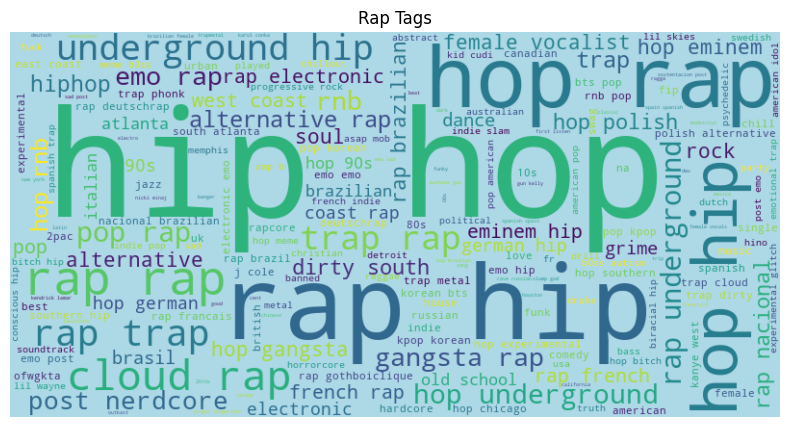

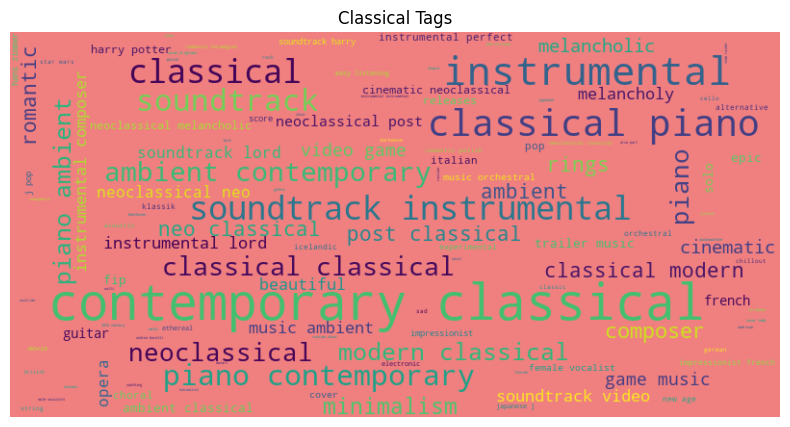

In [19]:
# Creating wordclouds for rap and classical genres
create_wordcloud(rap_tags, 'Rap Tags', color='lightblue')
create_wordcloud(classical_tags, 'Classical Tags', color='lightcoral')


### **Bar Chart**

Present the 10 most appeared tags grouped by the genre of the songs

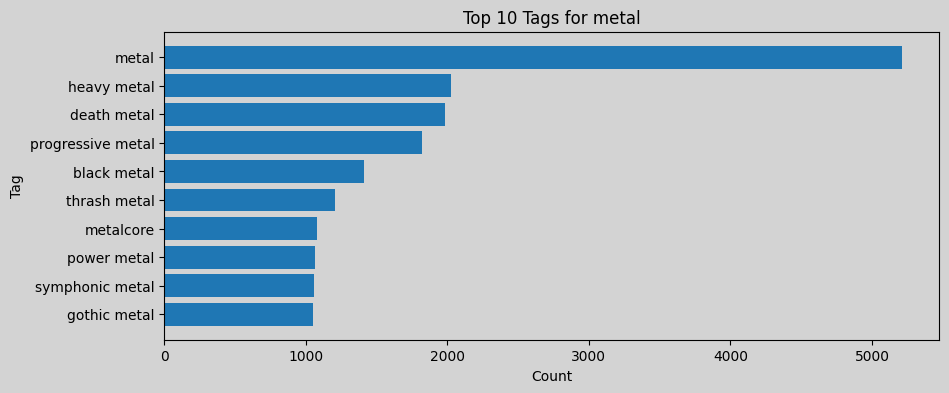

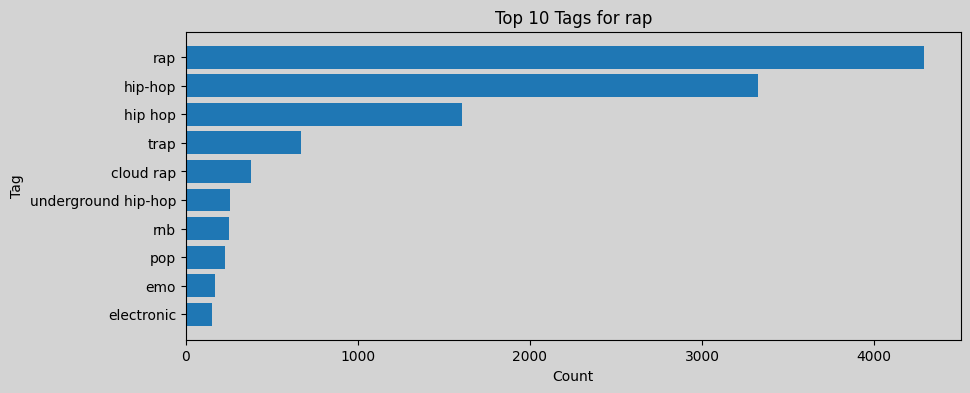

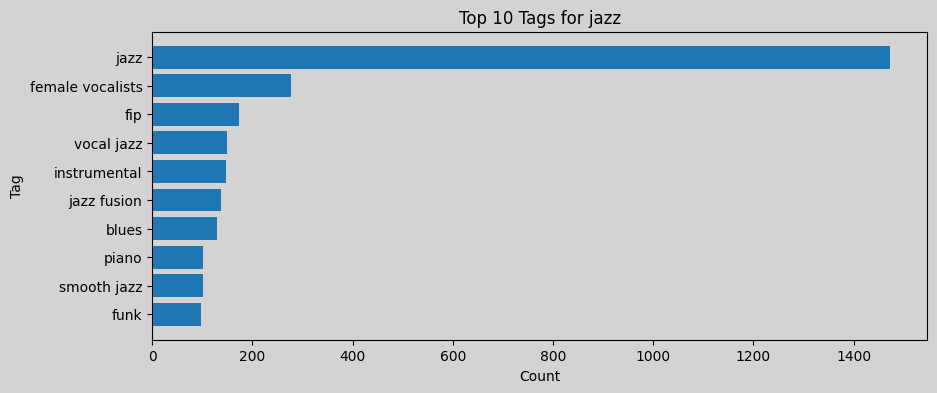

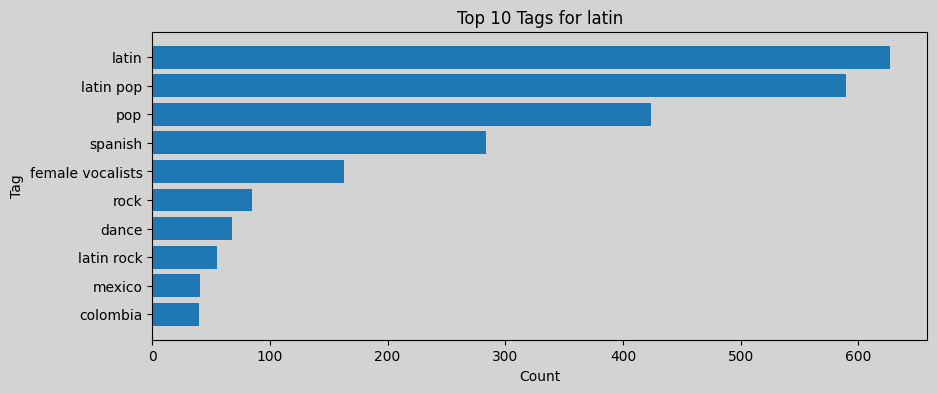

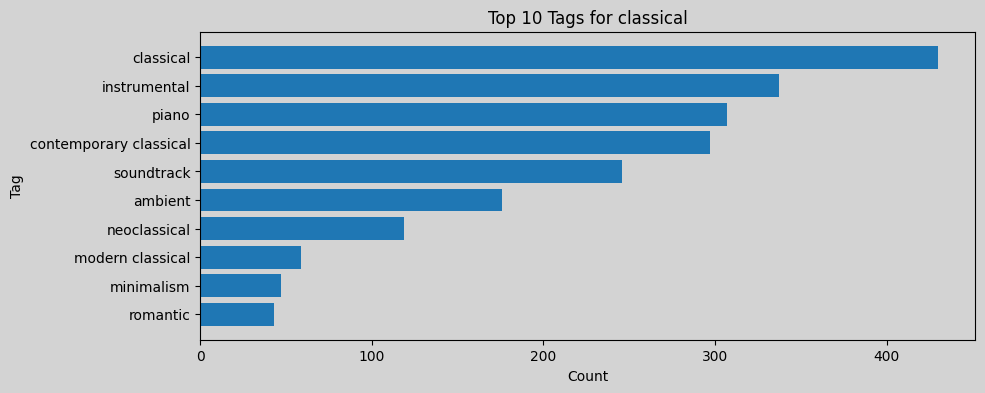

In [26]:
from collections import Counter
import matplotlib.pyplot as plt

data['tags_list'] = data['tags'].fillna('').apply(
    lambda x: [tag.strip() for tag in x.split(',') if tag.strip() != '']
)

for genre in data['main_genre'].unique():
    subset = data[data['main_genre'] == genre]

    all_tags = [tag for tags in subset['tags_list'] for tag in tags]

    tag_counts = Counter(all_tags)
    top_tags = tag_counts.most_common(10)

    tags, counts = zip(*top_tags)

    plt.figure(figsize=(10, 4)).patch.set_facecolor('lightgray')
    plt.barh(tags, counts)
    plt.gca().invert_yaxis()
    plt.gca().set_facecolor('lightgray')
    plt.title(f"Top 10 Tags for {genre}")
    plt.xlabel("Count")
    plt.ylabel("Tag")
    plt.show()

### **Dimensionality Reduction**

**Scatter Plot**  
We introduce the following function to help us compare the scatter plots between embedding generated on different bases.

In [27]:
from sklearn.manifold import TSNE

def scatter_plot_comparison(embed1, embed2, title1="PCA Embeddings", title2="Autoencoder Embeddings", data=data):

    # --- t-SNE visualization of the PCA and autoencoder embeddings ---
    tsne = TSNE(n_components=2, learning_rate=200, perplexity=50, max_iter=2000, random_state=42)
    X1 = tsne.fit_transform(embed1)
    X2 = tsne.fit_transform(embed2)

    # --- color the points by genre ---
    categories = data['main_genre'].astype('category')
    y = categories.cat.codes
    genre_names = categories.cat.categories

    # --- scatter plot of the t-SNE embeddings colored by genre ---
    fig, axes = plt.subplots(1,2, figsize=(12,6))

    scatter1 = axes[0].scatter(X1[:,0], X1[:,1], c=y, cmap='tab10', s=5)
    axes[0].set_title(title1)

    scatter2 = axes[1].scatter(X2[:,0], X2[:,1], c=y, cmap='tab10', s=5)
    axes[1].set_title(title2)

    handles, _ = scatter1.legend_elements()
    axes[1].legend(handles, genre_names, title="Genre", bbox_to_anchor=(1.05, 1), loc='upper left')

    plt.tight_layout()

    plt.show()




**Comparison between PCA and Autoencoder**

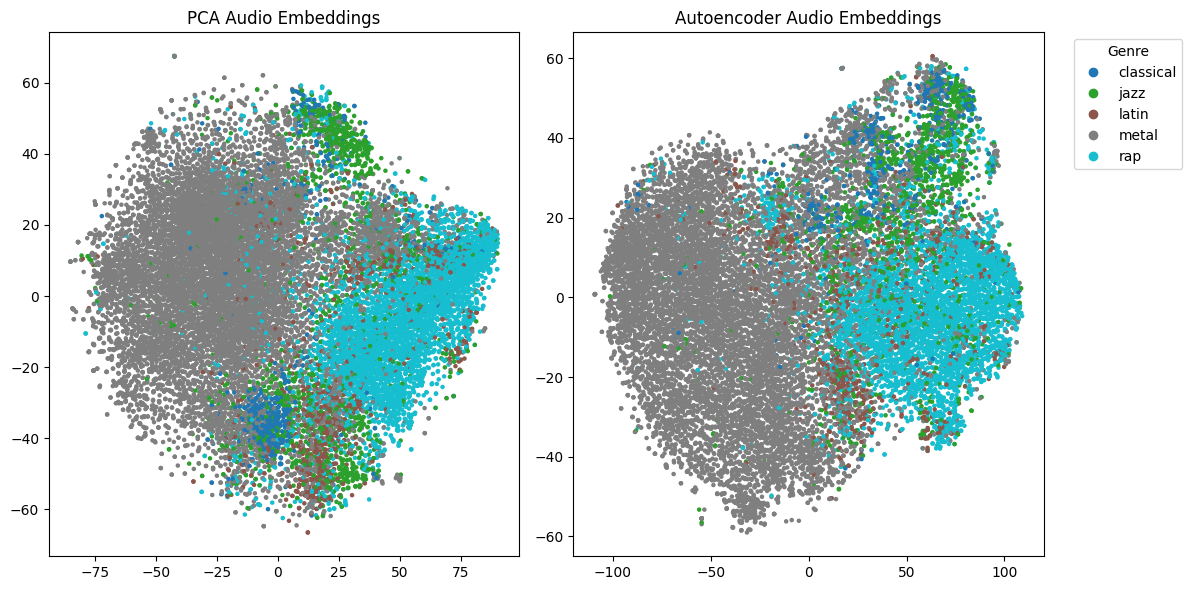

In [28]:
# --- Comparing the PCA and autoencoder embeddings with t-SNE visualization ---
scatter_plot_comparison(pca_audio_embeddings, autoenc_audio_embeddings, title1="PCA Audio Embeddings", title2="Autoencoder Audio Embeddings")

From the visualization of the audio embeddings (both PCA and Autoencoder-based), we can deduct that there is some patterns between the different genres. As we can see **metal** and **rap** have seemingly form distinctive clusters, while **latin** and **classical** music present also a similar pattern but less obvious. **Jazz** music is overlapping with latin and classical music showing that it has some resemblence with both.
In the next part, we will introduce classifiers to better capture the underlying structure of the data and improve genre discrimination.

**Comparison between Audio and Text Embeddings**

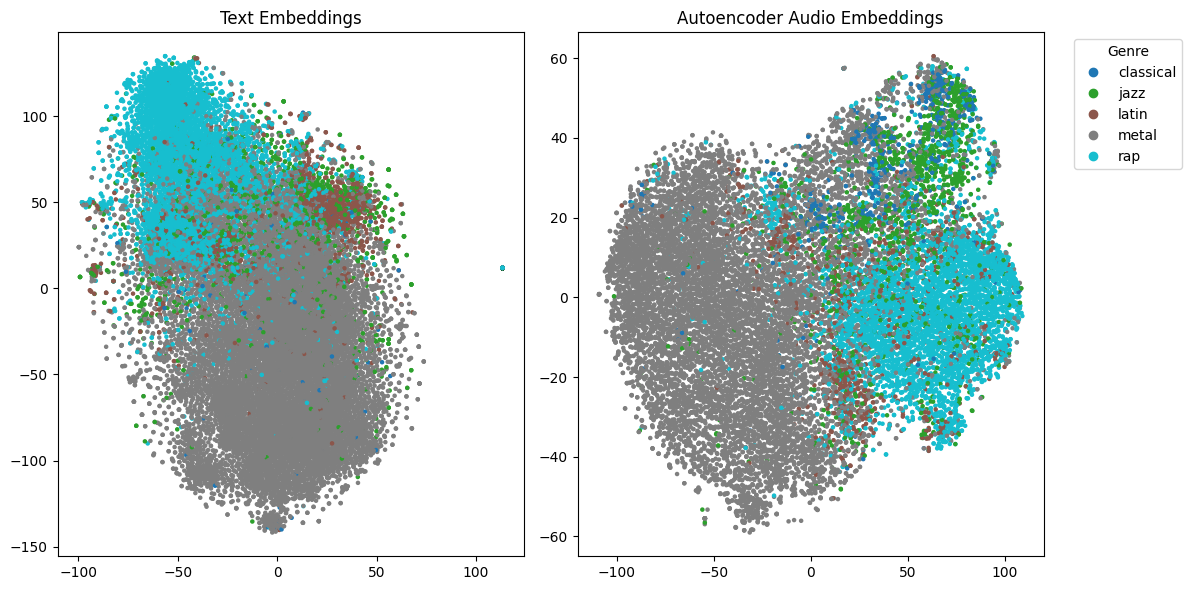

In [29]:
scatter_plot_comparison(embed1=text_embeddings_matrix, embed2=autoenc_audio_embeddings, title1="Text Embeddings", title2="Autoencoder Audio Embeddings")

The visualisation of text embeddings gives us also useful insight as far as the genres of the songs are concerned. It shows an even more strong cluster for **rap** music, a normal consequence as rap is based a lot on the lyrics and also shows a better clustering for  **latin**. The other 3 genres (**jazz**, **metal** and **classical**) shows similar pattern in the text and audio embeddings, a fact that reveals that they do not have a big difference between the uniqueness of their lyrics and their audio.

**Multiple-genres Songs**

In [30]:

# --- Function that distributes the song in bins, according to the number of genres they belong to ---
def num_of_genre_distribution():
    genre_count = data['genres'].apply(lambda x: len(x) if isinstance(x, list) else 0)
    max_num_genres_per_song = int(genre_count.max())
    # bin the songs that belong to more than 6 
    genre_count_binned = genre_count.apply(lambda x: f'>{max_num_genres_per_song-1}' if x > max_num_genres_per_song-1 else str(x))

    # frequence of each category
    order = [str(i) for i in range(1, max_num_genres_per_song)] + [f'>{max_num_genres_per_song-1}']
    counts = genre_count_binned.value_counts().reindex(order, fill_value=0)

    # plot
    plt.figure(figsize=(10, 6))
    counts.plot(kind='bar')

    plt.title('Distribution of songs according to the number of genres they belong to')
    plt.xlabel('Number of genres per song')
    plt.ylabel('Number of songs')
    plt.xticks(rotation=0)
    plt.tight_layout()
    plt.show()


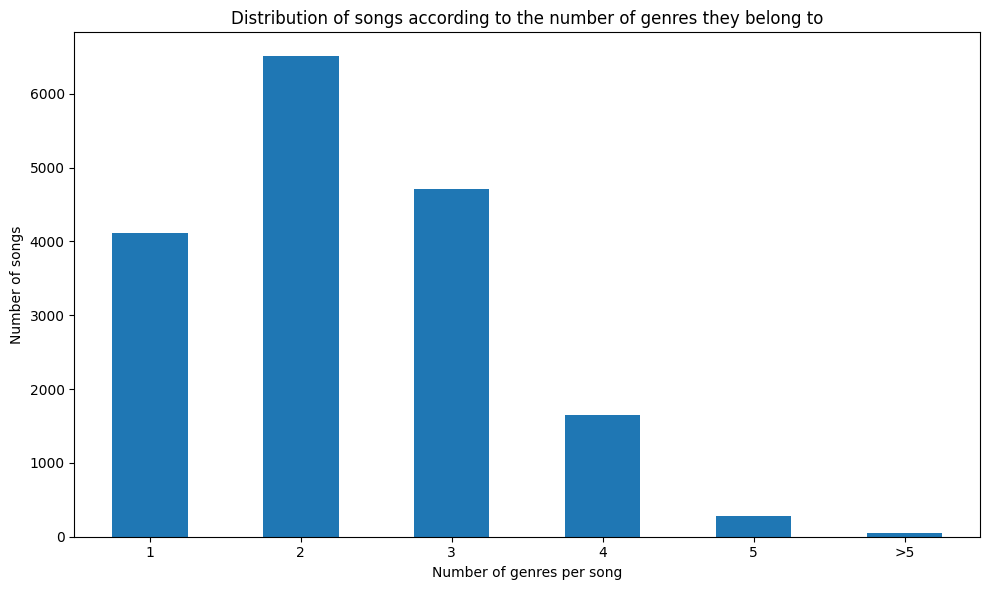

In [31]:
num_of_genre_distribution()

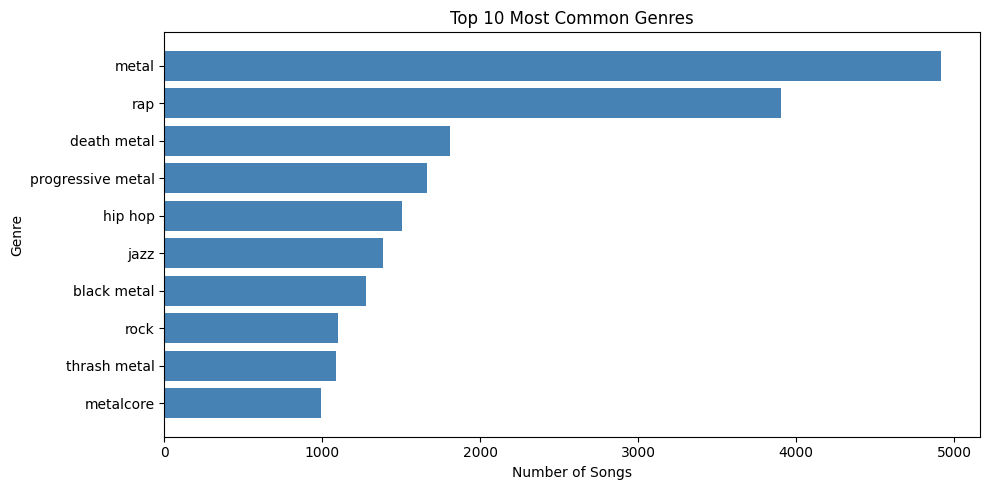

Genre                          Songs
-----------------------------------
metal                           4918
rap                             3901
death metal                     1810
progressive metal               1663
hip hop                         1507
jazz                            1382
black metal                     1275
rock                            1100
thrash metal                    1086
metalcore                        994


In [32]:
from collections import Counter
import matplotlib.pyplot as plt

# Extracting all different genres in one list
all_genres = [genre.strip() for genres in data['genres'] for genre in genres] 

# Count the appearances of each genre
genre_counts = Counter(all_genres)

# Top 10
top_n = 10
top_genres = genre_counts.most_common(top_n)
genres, counts = zip(*top_genres)

#Plot
plt.figure(figsize=(10, 5))
plt.barh(genres, counts, color='steelblue')
plt.gca().invert_yaxis()
plt.title(f"Top {top_n} Most Common Genres")
plt.xlabel("Number of Songs")
plt.ylabel("Genre")
plt.tight_layout()
plt.show()

# Results
print(f"{'Genre':<25} {'Songs':>10}")
print("-" * 35)
for genre, count in top_genres:
    print(f"{genre:<25} {count:>10}")

**Distribution of the songs based on their lyrics**

In [ ]:
import seaborn as sns
import re
import nltk

from nltk.corpus import stopwords
nltk.download('stopwords')

In [35]:

stop_words = set(stopwords.words('english'))

def clean_text(text):
    if pd.isna(text):
        return ""
    return str(text).lower()

def count_words(text):
    words = re.findall(r'\b\w+\b', clean_text(text))
    return len(words)

def count_chars(text):
    return len(clean_text(text))

def count_meaningful_words(text):
    words = re.findall(r'\b\w+\b', clean_text(text))
    words = [w for w in words if w not in stop_words]
    return len(words)

In [36]:
data['word_count'] = data['lyrics'].apply(count_words)
data['char_count'] = data['lyrics'].apply(count_chars)
data['meaningful_words'] = data['lyrics'].apply(count_meaningful_words)

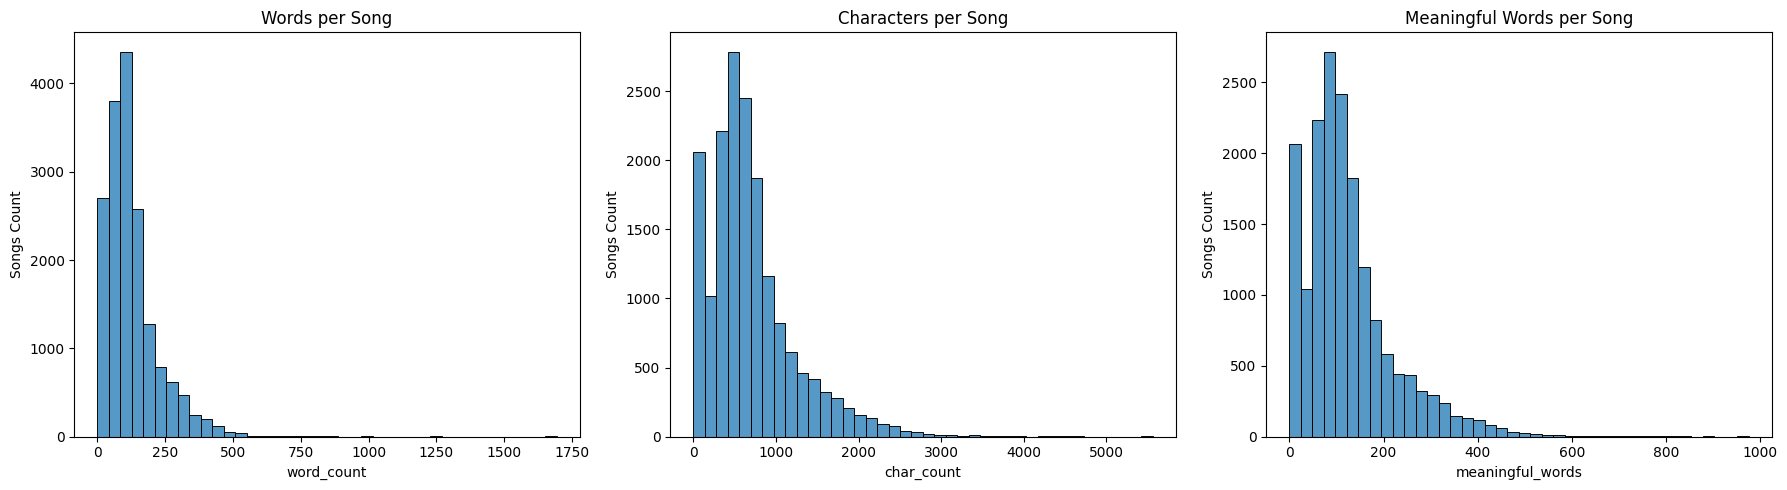

In [37]:
# --- Histograms ---
fig, axes = plt.subplots(1, 3, figsize=(18,5))

sns.histplot(data['word_count'], bins=40, ax=axes[0])
axes[0].set_title("Words per Song")
axes[0].set_ylabel("Songs Count")

sns.histplot(data['char_count'], bins=40, ax=axes[1])
axes[1].set_title("Characters per Song")
axes[1].set_ylabel("Songs Count")

sns.histplot(data['meaningful_words'], bins=40, ax=axes[2])
axes[2].set_title("Meaningful Words per Song")
axes[2].set_ylabel("Songs Count")

plt.tight_layout()
plt.show()

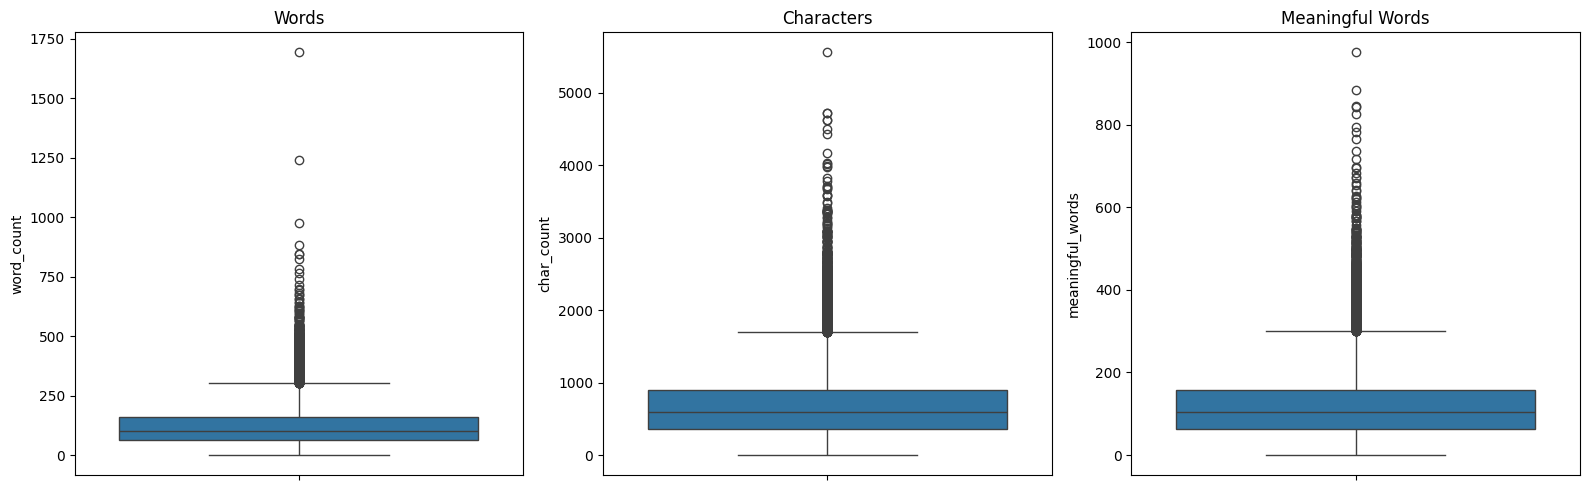

In [38]:
# --- boxplots ---
fig, axes = plt.subplots(1, 3, figsize=(16,5))

sns.boxplot(y=data['word_count'], ax=axes[0])
axes[0].set_title("Words")

sns.boxplot(y=data['char_count'], ax=axes[1])
axes[1].set_title("Characters")

sns.boxplot(y=data['meaningful_words'], ax=axes[2])
axes[2].set_title("Meaningful Words")

plt.tight_layout()
plt.show()

We present results of the distribution of lyrics per song using histograms and boxplots for the three categories that we measure(words count, characters count, meaningful words count).  

The plots show that most songs have a relatively small to medium amount of lyrics, while fewer songs contain very long lyrics. This creates a right-skewed distribution, with many songs grouped at lower values and some extreme outliers.  

Most songs have around 50–200 words and under 1,000 characters. A small number of songs are much longer and contain far more words than average.  

After removing stopwords, the number of words decreases, but the overall pattern stays the same. This means longer songs still contain more meaningful lyrical content.  
In general, most songs are fairly short in terms of lyrics, while only a few are very text-heavy.

**Sentiment Analysis on the lyrics**

For the sentiment analysis, we choose to distinctive music genres, *metal* and *latin*. Latin songs are generally more happy, focusing on make the audience ready to dance and party. On the other hand, metal songs are more full of anger and sadness.

In [ ]:
from nltk.sentiment import SentimentIntensityAnalyzer

nltk.download('vader_lexicon')

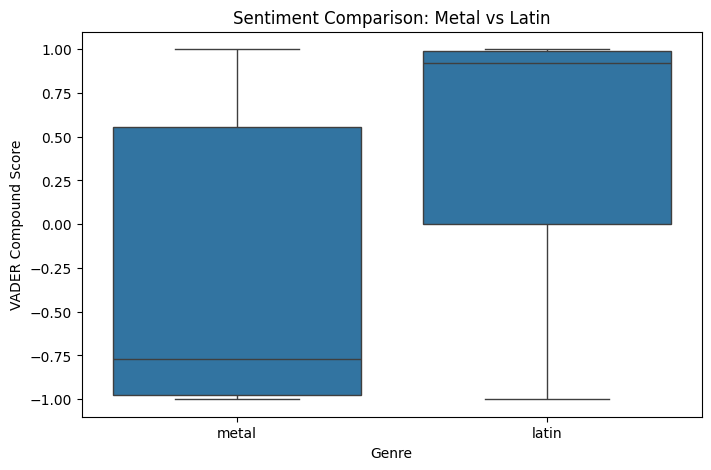

In [41]:

sia = SentimentIntensityAnalyzer()

# sentiment score from lyrics
data['sentiment'] = data['lyrics'].fillna('').apply(
    lambda x: sia.polarity_scores(str(x))['compound']
)

# keep songs that contain metal or latin
subset = data[data['genres'].apply(
    lambda g: isinstance(g, list) and ('metal' in g or 'latin' in g)
)].copy()

# assign comparison label
def pick_genre(g):
    if 'metal' in g:
        return 'metal'
    elif 'latin' in g:
        return 'latin'
    return None

subset['genre_group'] = subset['genres'].apply(pick_genre)

# boxplot
plt.figure(figsize=(8, 5))
sns.boxplot(data=subset, x='genre_group', y='sentiment')
plt.title("Sentiment Comparison: Metal vs Latin")
plt.xlabel("Genre")
plt.ylabel("VADER Compound Score")
plt.show()

This boxplot compares the sentiment of song lyrics between Metal and Latin songs using the VADER compound score, which ranges from -1 (**very negative**) to +1 (**very positive**).

The plot shows a clear difference between the two genres. Metal songs tend to have much lower sentiment scores overall, with a median close to -0.8, indicating that their lyrics are generally more negative, darker, or aggressive in tone. Most Metal songs are concentrated in the negative range, although a few songs also have positive sentiment.

In contrast, Latin songs show much higher sentiment values, with a median close to 0.95, meaning their lyrics are mostly positive, cheerful, or emotionally uplifting. Most Latin songs are concentrated near the positive end of the scale, with only a few lower-scoring cases.

Overall, this result supports the hypothesis that different music genres express different emotional tones in their lyrics. In this dataset, Metal appears more negative, while Latin appears significantly more positive.

### **Cosine Similarity**

In [42]:
from sklearn.metrics.pairwise import cosine_similarity

similarity_matrix_autoenc = cosine_similarity(autoenc_audio_embeddings)
similarity_matrix_pca = cosine_similarity(pca_audio_embeddings)
similarity_matrix_text = cosine_similarity(text_embeddings_matrix)

def top_n_similar_songs(song_pos, data, similarity_matrix=similarity_matrix_autoenc, n=5):
    
    similarity_df = pd.DataFrame(similarity_matrix, index=data['id'], columns=data['id'])
    song_id = data['id'].iloc[song_pos]      
    
    similar_songs = similarity_df.loc[song_id].sort_values(ascending=False)[1:n+1]
    similar_songs_ids = similar_songs.index.tolist()
    similar_songs_names = data[data['id'].isin(similar_songs_ids)][["song","main_genre"]]
    
    return similar_songs_names



**Cosine similarity: PCA vs Autoencoder**  


In [48]:
# --- Example: top 5 similar songs to i-th song in the dataset using audio embeddings ---
song_position = 1
top_5_similar_songs_enc = top_n_similar_songs(song_pos=song_position, data=data, similarity_matrix=similarity_matrix_autoenc, n=5)
print("Top 5 similar songs to the " + data['song'].iloc[song_position] + "' (Autoencoder):")
print(top_5_similar_songs_enc)

top_5_similar_songs_pca = top_n_similar_songs(song_pos=song_position, data=data, similarity_matrix=similarity_matrix_pca, n=5)
print("Top 5 similar songs to the " + data['song'].iloc[song_position] + "' (PCA):")
print(top_5_similar_songs_pca)

Top 5 similar songs to the Sign of the Times' (Autoencoder):
                           song main_genre
2490   Communion and the Oracle      metal
7170                    Vicious      metal
11272    Breaking All Illusions      metal
12561            If I Could Fly      metal
13483                Galswintha      metal
Top 5 similar songs to the Sign of the Times' (PCA):
                     song main_genre
462         Original Face      metal
4977     One Last Goodbye      metal
7502      Veil of Elysium      metal
15274  A Life Left Behind      metal
16246               Peace      metal



After experimenting on the cosine similarity of the songs and extracting the top-5 similar songs of a variety of songs using the PCA embeddings and the autoencoder embeddings, we notice that similarity results differ between PCA-based and Autoencoder-based embeddings, indicating that each method captures different aspects of the audio data.  
PCA is a linear dimensionality reduction technique that is based on the variance. As a result, it tends to capture more global and general characteristics of the songs and brings close songs with similar high-level structure.  
The Autoencoder, as a non-linear model, learns more complex similarity patterns between the songs and possibly can capture more deep relationships between the MFCC stats.  
Different embedding methods emphasize different properties of the data, leading to different nearest-neighbor relationships between songs.


**Cosine Similarity: Audio Embeddings vs Text Embeddings**

In [49]:
# --- Top 5 similar songs: Comparison between text and audio embeddings ---
song_position = 1
top_5_similar_songs_enc = top_n_similar_songs(song_pos=song_position, data=data, similarity_matrix=similarity_matrix_autoenc, n=5)
print("Top 5 similar songs to the " + data['song'].iloc[song_position] + "' (Autoencoder):")
print(top_5_similar_songs_enc)

top_5_similar_songs_pca = top_n_similar_songs(song_pos=song_position, data=data, similarity_matrix=similarity_matrix_pca, n=5)
print("Top 5 similar songs to the " + data['song'].iloc[song_position] + "' (PCA):")
print(top_5_similar_songs_pca)

top_n_similar_songs_text = top_n_similar_songs(song_pos=song_position, data=data, similarity_matrix=similarity_matrix_text, n=5)
print("Top 5 similar songs to the " + data['song'].iloc[song_position] + "' (Text):")
print(top_n_similar_songs_text)

Top 5 similar songs to the Sign of the Times' (Autoencoder):
                           song main_genre
2490   Communion and the Oracle      metal
7170                    Vicious      metal
11272    Breaking All Illusions      metal
12561            If I Could Fly      metal
13483                Galswintha      metal
Top 5 similar songs to the Sign of the Times' (PCA):
                     song main_genre
462         Original Face      metal
4977     One Last Goodbye      metal
7502      Veil of Elysium      metal
15274  A Life Left Behind      metal
16246               Peace      metal
Top 5 similar songs to the Sign of the Times' (Text):
                        song main_genre
661    Falling Back To Earth      metal
2600               Saturnine      metal
4544       Reflect The Storm      metal
11016             Glory Ride      metal
11052          The Scarecrow      metal


***Comparison of the different Embeddings***

We present a small comparison between the different embeddings to reveal which one "groups" together better songs of the same genre. Our metric is the average recall for the each type of embeddings, that shows at which percentage the k-Nearest Neighbors of a query songs belong to the same category as the query.  
The metric is not absolute and we do not compare with a ground truth, we just make an observation about the "clustering" of the songs. We realise that a song can be similar with a song of different category but in general we assume that similar songs are more probable (therefore "correct") to belong to the same category.

In [50]:
'''
Function to calculate the recall@n of the nearest neighbors
that actually belong to the same 'genre' like the query.

Purpose of the function is to analyse which embeddings( Audio(PCA and Autoencoder) or Text )
are bringing "closer" data of the same genre.
'''
def recall_of_same_genre(data, indices, similarity_matrix, n=10):
    total_recall = 0

    for i in indices:
        song_genre = data["main_genre"].iloc[i]

        similarities = similarity_matrix[i].copy()
        similarities[i] = -1
        top_indices = np.argsort(similarities)[-n:][::-1]

        top_genres = data.iloc[top_indices]["main_genre"].to_list()
        same = sum(genre == song_genre for genre in top_genres)

        total_recall += same / n

    return total_recall / len(indices)


In [51]:
embed_types = ["Autoencoder", "PCA", "TEXT"]

# pick random indices
np.random.seed(42)
random_indices = np.random.choice(len(data), size=2000, replace=False)
results = [
    recall_of_same_genre(data, random_indices, similarity_matrix=similarity_matrix_autoenc),
    recall_of_same_genre(data, random_indices, similarity_matrix=similarity_matrix_pca),
    recall_of_same_genre(data, random_indices, similarity_matrix=similarity_matrix_text),
    ]

header = " | ".join([f"{name:^15}" for name in embed_types])
separator = "-"*len(header)
values = " | ".join([f"{val:^15.4f}" for val in results])

print(separator)
print(header)
print(separator)
print(values)
print(separator)

---------------------------------------------------
  Autoencoder   |       PCA       |      TEXT      
---------------------------------------------------
    0.7627      |     0.7840      |     0.7051     
---------------------------------------------------
